# Supervised Learning Experiments

Run all cells in order. Start this notebook from the repository root or the `docs` directory.
Datasets are read from `docs/`, algorithm implementations are imported from `src/`, and generated files belong in `output/`.


---

# Initialization <a name="2"></a>

---

## Import Libraries

Every import of the notebook is kept in this cell.

In [316]:
%pip install matplotlib numpy pandas scikit-learn cvxpy


Note: you may need to restart the kernel to use updated packages.


In [317]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, OrdinalEncoder

from sklearn.feature_selection import SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.decomposition import PCA

# Support starting the notebook from the repository root or docs directory.
ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "src").is_dir():
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


## Settings

Paths and shared constants are kept in this class.

In [318]:
class Settings:
    SEED = 42
    DATA_DIR = ROOT_DIR / "docs"
    OUTPUT_DIR = ROOT_DIR / "output"

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [319]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [320]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding <a name="3"></a>

---

## Explore Data
Memahami nya seperti memahami dia


In [321]:
print(train_df.shape)
train_df.dtypes

(27373, 19)


id                              str
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking               float64
room_category                   str
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64
dtype: object

In [322]:
train_df.head()

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [323]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


#### Distribusi Fitur Kategorikal

In [324]:
train_df["meal_package"].value_counts()


meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64

In [325]:
train_df["room_category"].value_counts()

room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

In [326]:
train_df["booking_channel"].value_counts()

booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

####  Distribusi is_cancelled

In [327]:
print(train_df["is_canceled"].value_counts())
print(train_df["is_canceled"].value_counts(normalize=True))

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    0.672341
1    0.327659
Name: proportion, dtype: float64


In [328]:
pd.crosstab(
    train_df["booking_channel"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
booking_channel,,
Airline,0.693182,0.306818
Complimentary,1.000000,0.000000
Corporate,0.884997,0.115003
Offline Agent,0.698492,0.301508
Online Travel Agent,0.636343,0.363657


In [329]:
pd.crosstab(
    train_df["meal_package"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
meal_package,,
Breakfast,0.688562,0.311438
Full Board,0.750000,0.250000
Half Board,0.540589,0.459411
Room Only,0.661998,0.338002


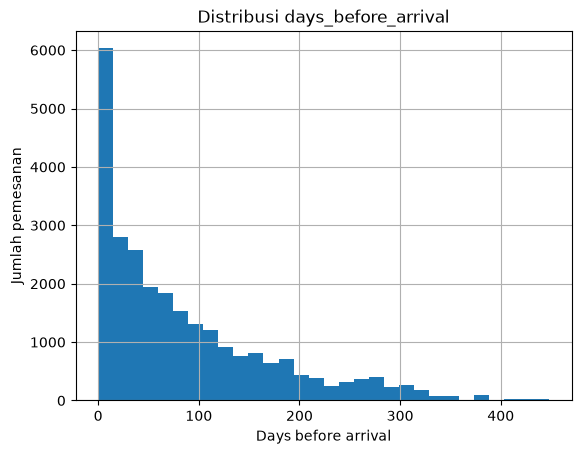

In [330]:
train_df["days_before_arrival"].hist(bins=30)
plt.xlabel("Days before arrival")
plt.ylabel("Jumlah pemesanan")
plt.title("Distribusi days_before_arrival")
plt.show()

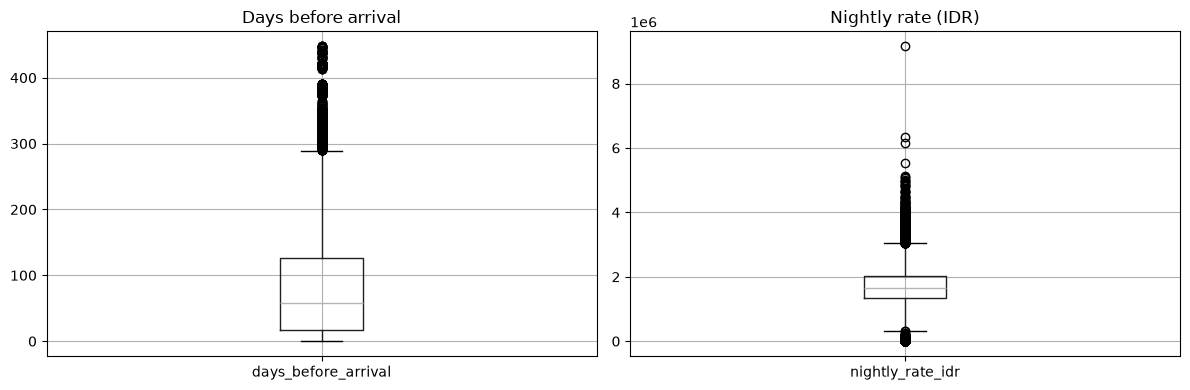

In [331]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df.boxplot(column="days_before_arrival", ax=axes[0])
axes[0].set_title("Days before arrival")

train_df.boxplot(column="nightly_rate_idr", ax=axes[1])
axes[1].set_title("Nightly rate (IDR)")

plt.tight_layout()
plt.show()

In [332]:
train_df.groupby("is_canceled")["days_before_arrival"].describe()

,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,17631.0,58.913221,63.722946,0.0,10.0,38.0,86.0,390.0
1,8619.0,139.518622,99.195754,0.0,55.0,123.0,205.5,448.0


## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [333]:
feature_cols = test_df.columns

missing_summary = pd.DataFrame({
    "train": train_df[feature_cols].isna().sum(),
    "test": test_df.isna().sum()
})

missing_summary[missing_summary.sum(axis=1) > 0]

,train,test
num_adults,809,180
num_children,3035,747
meal_package,1760,442
needs_parking,1082,247
room_category,1002,242
days_before_arrival,1123,290
nightly_rate_idr,2038,540
special_requests,2500,593


In [334]:
print("Duplikat baris train:", train_df.duplicated().sum())
print("ID duplikat train:", train_df["id"].duplicated().sum())

print("Duplikat baris test:", test_df.duplicated().sum())
print("ID duplikat test:", test_df["id"].duplicated().sum())


Duplikat baris train: 0
ID duplikat train: 0
Duplikat baris test: 0
ID duplikat test: 0


In [335]:
nonnegative_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
]

train_df[nonnegative_cols].lt(0).sum()

num_adults                  0
num_children                0
weekend_nights              0
weekday_nights              0
days_before_arrival         0
prior_cancellations         0
prior_completed_bookings    0
nightly_rate_idr            0
special_requests            0
dtype: int64

In [336]:
print("num_adults = 0:", (train_df["num_adults"] == 0).sum())
print("arrival_month di luar 1–12:", (~train_df["arrival_month"].between(1, 12)).sum())
print("arrival_day di luar 1–31:", (~train_df["arrival_day"].between(1, 31)).sum())

num_adults = 0: 106
arrival_month di luar 1–12: 0
arrival_day di luar 1–31: 0


In [337]:
train_features = train_df.drop(columns="is_canceled")

print("Kolom train dan test sama:", train_features.columns.equals(test_df.columns))

for col in ["meal_package", "room_category", "booking_channel"]:
    unseen = set(test_df[col].dropna().unique()) - set(train_df[col].dropna().unique())
    print(f"{col}, kategori baru di test:", unseen)

Kolom train dan test sama: True
meal_package, kategori baru di test: set()
room_category, kategori baru di test: set()
booking_channel, kategori baru di test: set()


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [338]:
ID_COL = "id"
TARGET_COL = "is_canceled"

X = train_df.drop(columns=[ID_COL, TARGET_COL])
y = train_df[TARGET_COL].astype(int)
X_test = test_df.drop(columns=[ID_COL])
test_ids = test_df[ID_COL].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=CFG.SEED
)

pd.Series({
    "X_train": len(X_train),
    "X_val": len(X_val),
    "X_test": len(X_test),
})


X_train    21898
X_val       5475
X_test      6844
dtype: int64

---

# Data Preparation <a name="5"></a>

---

## Select Data

In [339]:
train_ids = train_df.loc[X_train.index, ID_COL].copy()
val_ids = train_df.loc[X_val.index, ID_COL].copy()

X_train_raw = X_train.copy()
X_val_raw = X_val.copy()
X_test_raw = X_test.copy()

print("Jumlah fitur:", X_train.shape[1])
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape)


Jumlah fitur: 17
Train: (21898, 17) (21898,)
Validation: (5475, 17) (5475,)
Test: (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

In [340]:
num_col = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "needs_parking", "days_before_arrival", "arrival_year",
    "arrival_month", "arrival_day", "is_returning_guest",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests",
]
cat_col = ["meal_package", "room_category", "booking_channel"]


### Missing Values

In [341]:
train_zero_adults = X_train_raw["num_adults"].eq(0)
val_zero_adults = X_val_raw["num_adults"].eq(0)
test_zero_adults = X_test_raw["num_adults"].eq(0)

print("num_adults = 0 pada train:", int(train_zero_adults.sum()))
print("num_adults = 0 pada validation:", int(val_zero_adults.sum()))
print("num_adults = 0 pada test:", int(test_zero_adults.sum()))

X_train_raw.loc[train_zero_adults, "num_adults"] = np.nan
X_val_raw.loc[val_zero_adults, "num_adults"] = np.nan
X_test_raw.loc[test_zero_adults, "num_adults"] = np.nan

numeric_fill_values = X_train_raw[num_col].median()
categorical_fill_values = X_train_raw[cat_col].mode(dropna=True).iloc[0]

def impute_missing_values(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()
    result[num_col] = result[num_col].fillna(numeric_fill_values)
    result[cat_col] = result[cat_col].fillna(categorical_fill_values)
    return result

X_train_imputed = impute_missing_values(X_train_raw)
X_val_imputed = impute_missing_values(X_val_raw)
X_test_imputed = impute_missing_values(X_test_raw)

print("Missing value setelah imputasi (train):", int(X_train_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (validation):", int(X_val_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (test):", int(X_test_imputed.isna().sum().sum()))

num_adults = 0 pada train: 84
num_adults = 0 pada validation: 22
num_adults = 0 pada test: 22
Missing value setelah imputasi (train): 0
Missing value setelah imputasi (validation): 0
Missing value setelah imputasi (test): 0


### Duplicates

In [342]:
train_rows = X_train_raw.copy()
train_rows[ID_COL] = train_ids
train_rows[TARGET_COL] = y_train
val_rows = X_val_raw.copy()
val_rows[ID_COL] = val_ids
val_rows[TARGET_COL] = y_val

print("Duplikat train:", int(train_rows.duplicated().sum()))
print("Duplikat validation:", int(val_rows.duplicated().sum()))
print("Duplikat test:", int(test_df.duplicated().sum()))

X_train_clean = X_train_imputed.copy()
X_val_clean = X_val_imputed.copy()
X_test_clean = X_test_imputed.copy()


Duplikat train: 0
Duplikat validation: 0
Duplikat test: 0


### Outliers

In [343]:
outlier_cols = [
    "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr", "special_requests",
]
outlier_counts = {}

for col in outlier_cols:
    values = X_train_raw[col].dropna()
    if col == "nightly_rate_idr":
        values = values[values > 0]
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    source = X_train_raw[col]
    eligible = source.notna()
    if col == "nightly_rate_idr":
        eligible &= source > 0
    outlier_counts[col] = int((eligible & ((source < lower) | (source > upper))).sum())

pd.Series(outlier_counts, name="kandidat_outlier_IQR")


num_children                1613
weekend_nights                13
weekday_nights               201
days_before_arrival          755
prior_cancellations          183
prior_completed_bookings     478
nightly_rate_idr             574
special_requests             456
Name: kandidat_outlier_IQR, dtype: int64

### Data Errors

In [344]:
negative_counts = X_train_raw[num_col].lt(0).sum()

binary_cols = ["needs_parking", "is_returning_guest", TARGET_COL]
binary_values = X_train_raw[["needs_parking", "is_returning_guest"]].copy()
binary_values[TARGET_COL] = y_train
invalid_binary_counts = (
    (~binary_values[binary_cols].isin([0, 1]) & binary_values[binary_cols].notna()).sum()
)

arrival_dates = pd.to_datetime(
    X_train_raw[["arrival_year", "arrival_month", "arrival_day"]]
    .rename(columns={
        "arrival_year": "year",
        "arrival_month": "month",
        "arrival_day": "day",
    }),
    errors="coerce",
)
invalid_arrival_dates = int(arrival_dates.isna().sum())

print("Nilai numerik negatif:", negative_counts[negative_counts > 0].to_dict())
print("Nilai biner di luar 0/1:", invalid_binary_counts[invalid_binary_counts > 0].to_dict())
print("Tanggal kedatangan tidak valid:", invalid_arrival_dates)


Nilai numerik negatif: {}
Nilai biner di luar 0/1: {}
Tanggal kedatangan tidak valid: 0


## Data Transformation

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [345]:
scaled_numeric_cols = num_col.copy()
scaler = RobustScaler()

X_train_scaled = X_train_clean.copy()
X_val_scaled = X_val_clean.copy()
X_test_scaled = X_test_clean.copy()

X_train_scaled[scaled_numeric_cols] = scaler.fit_transform(X_train_clean[scaled_numeric_cols])
X_val_scaled[scaled_numeric_cols] = scaler.transform(X_val_clean[scaled_numeric_cols])
X_test_scaled[scaled_numeric_cols] = scaler.transform(X_test_clean[scaled_numeric_cols])

print("Jumlah fitur numerik yang distandardisasi:", len(scaled_numeric_cols))


Jumlah fitur numerik yang distandardisasi: 14


### Encoding

This part covers the numeric representation of categorical attributes.

In [347]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train_scaled[cat_col])

encoded_feature_names = list(encoder.get_feature_names_out(cat_col))

meal_package_order = [
    "Room Only",
    "Breakfast",
    "Half Board",
    "Full Board",
]

meal_package_encoder = OrdinalEncoder(
    categories=[meal_package_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

meal_package_encoder.fit(X_train_scaled[["meal_package"]])

def combine_scaled_and_encoded(data: pd.DataFrame) -> pd.DataFrame:
    numeric_part = data[scaled_numeric_cols].copy()

    categorical_part = pd.DataFrame(
        encoder.transform(data[cat_col]),
        columns=encoded_feature_names,
        index=data.index,
    )

    categorical_part = categorical_part.drop(
        columns=[
            col for col in encoded_feature_names
            if col.startswith("meal_package_")
        ]
    )

    categorical_part["meal_package"] = meal_package_encoder.transform(
        data[["meal_package"]]
    ).ravel()

    return pd.concat([numeric_part, categorical_part], axis=1)

X_train_encoded = combine_scaled_and_encoded(X_train_scaled)
X_val_encoded = combine_scaled_and_encoded(X_val_scaled)
X_test_encoded = combine_scaled_and_encoded(X_test_scaled)

print("Bentuk fitur train:", X_train_encoded.shape)
print("Bentuk fitur validation:", X_val_encoded.shape)
print("Bentuk fitur test:", X_test_encoded.shape)

Bentuk fitur train: (21898, 27)
Bentuk fitur validation: (5475, 27)
Bentuk fitur test: (6844, 27)


## Feature Selection

Remove constant features, then rank the remaining encoded features using mutual
information with the target. Keep up to 15 features as an experimental subset;
this is a starting point, not a claim that 15 is optimal. Compare this subset with
all features during model validation before choosing the final representation.

Both steps are fitted on the original training split only, before oversampling.
Validation and Kaggle test data only receive the fitted transformations.

Reference: https://scikit-learn.org/stable/modules/feature_selection.html

Removed constant features: []
Feature scores:
days_before_arrival                    1.054516e-01
special_requests                       4.158404e-02
arrival_month                          2.709663e-02
nightly_rate_idr                       2.502356e-02
arrival_year                           2.456089e-02
prior_completed_bookings               9.457885e-03
is_returning_guest                     8.396625e-03
booking_channel_Corporate              6.796644e-03
booking_channel_Online Travel Agent    5.402483e-03
booking_channel_Complimentary          4.435582e-03
needs_parking                          4.223668e-03
weekend_nights                         4.181798e-03
num_adults                             3.982429e-03
meal_package                           3.238631e-03
arrival_day                            1.579500e-03
prior_cancellations                    7.718927e-04
booking_channel_Offline Agent          7.221817e-04
room_category_Type A                   5.127590e-04
room_category_Type

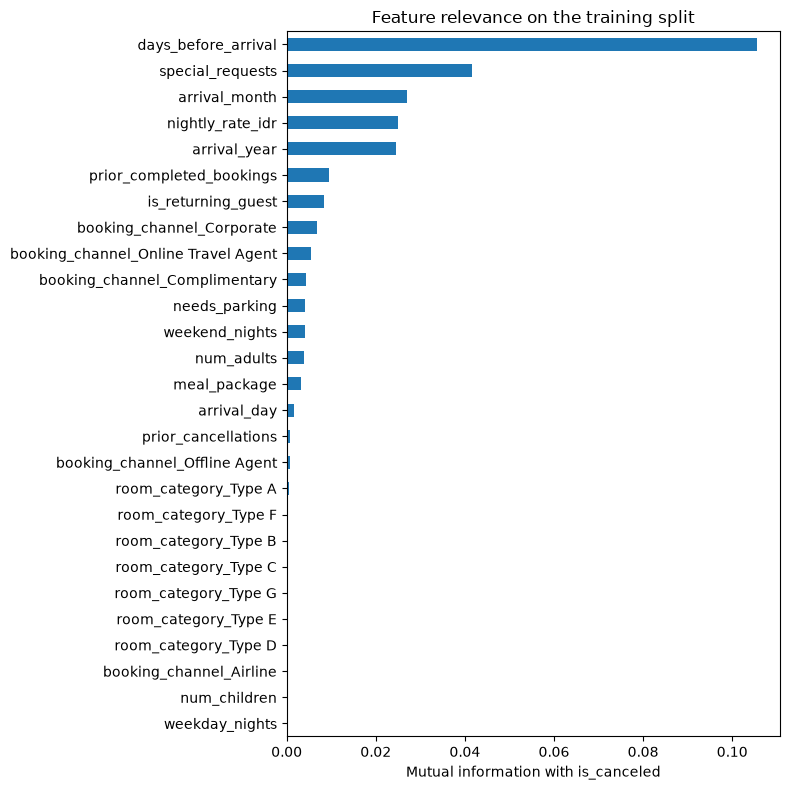

In [348]:
constant_filter = VarianceThreshold(threshold=0.0)
constant_filter.fit(X_train_encoded)
nonconstant_cols = X_train_encoded.columns[constant_filter.get_support()].tolist()
removed_constant_cols = X_train_encoded.columns[~constant_filter.get_support()].tolist()

# One-hot columns and binary flags are discrete, even after scaling.
discrete_features = np.array([
    col not in scaled_numeric_cols or col in ["needs_parking", "is_returning_guest"]
    for col in nonconstant_cols
])


def score_features(X, y):
    values = np.array(X, dtype=float, copy=True)
    # Give discrete features integer codes after their earlier standardization.
    for i, is_discrete in enumerate(discrete_features):
        if is_discrete:
            _, values[:, i] = np.unique(values[:, i], return_inverse=True)
    return mutual_info_classif(
        values, y, discrete_features=discrete_features, random_state=CFG.SEED
    )


SELECT_K = min(15, len(nonconstant_cols))
selector = SelectKBest(score_func=score_features, k=SELECT_K)
selector.fit(X_train_encoded[nonconstant_cols], y_train)
selected_cols = np.array(nonconstant_cols)[selector.get_support()].tolist()

feature_scores = pd.Series(
    selector.scores_, index=nonconstant_cols, name="mutual_information"
).sort_values(ascending=False)
print("Removed constant features:", removed_constant_cols)
print("Feature scores:")
print(feature_scores)
print("Selected features:", selected_cols)

X_train_selected = X_train_encoded[selected_cols].copy()
X_val_selected = X_val_encoded[selected_cols].copy()
X_test_selected = X_test_encoded[selected_cols].copy()

feature_scores.sort_values().plot.barh(figsize=(8, 8))
plt.xlabel("Mutual information with is_canceled")
plt.title("Feature relevance on the training split")
plt.tight_layout()
plt.show()

## Dimensionality Reduction

PCA is a separate experiment on the selected features. Standardize its input,
including the one-hot columns, so PCA does not depend on differences in feature
scales. Retain at least 95% of the training variance. This percentage describes
feature variance, not classification accuracy.

Fit the additional scaler and PCA only on training data, before oversampling.
Keep the full, selected, and PCA representations for later validation comparisons.
PCA components are numeric and should not be passed to the categorical part of
mixed Naive Bayes. Its original categorical input is preserved separately below.

Reference: https://scikit-learn.org/stable/modules/decomposition.html#pca

Selected feature count: 15
PCA component count: 13
Retained variance: 0.950153490574731


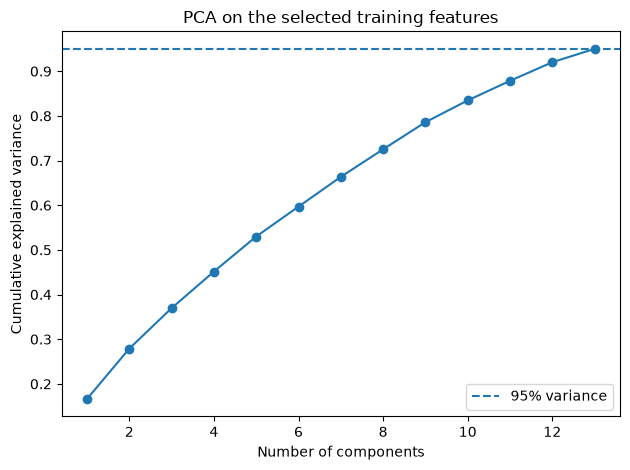

In [349]:
pca_scaler = StandardScaler()
pca_train = pca_scaler.fit_transform(X_train_selected)
pca_val = pca_scaler.transform(X_val_selected)
pca_test = pca_scaler.transform(X_test_selected)

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pd.DataFrame(pca.fit_transform(pca_train), index=X_train_selected.index)
X_val_pca = pd.DataFrame(pca.transform(pca_val), index=X_val_selected.index)
X_test_pca = pd.DataFrame(pca.transform(pca_test), index=X_test_selected.index)

print("Selected feature count:", len(selected_cols))
print("PCA component count:", pca.n_components_)
print("Retained variance:", pca.explained_variance_ratio_.sum())

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA on the selected training features")
plt.legend()
plt.tight_layout()
plt.show()

### Class Balance

In [350]:
y_train_cv = y_train.reset_index(drop=True).copy()

class_balance = pd.DataFrame({
    "jumlah": y_train.value_counts().sort_index(),
    "proporsi": y_train.value_counts(normalize=True).sort_index(),
})
class_balance.index.name = TARGET_COL
print("Distribusi sebelum oversampling:")
print(class_balance)

majority_indices = y_train[y_train == 0].index
minority_indices = y_train[y_train == 1].sample(
    n=len(majority_indices),
    replace=True,
    random_state=CFG.SEED,
).index
balanced_indices = majority_indices.append(minority_indices)
balanced_indices = pd.Series(balanced_indices).sample(
    frac=1,
    random_state=CFG.SEED,
).to_numpy()

X_train_final = X_train_encoded.loc[balanced_indices].reset_index(drop=True)
y_train_final = y_train.loc[balanced_indices].reset_index(drop=True)
X_val_final = X_val_encoded.copy()
X_test_final = X_test_encoded.copy()

print("Distribusi training setelah oversampling:")
print(y_train_final.value_counts().sort_index())


# Apply the same sampled row indices to each representation.
X_train_selected_final = X_train_selected.loc[balanced_indices].reset_index(drop=True)
X_val_selected_final = X_val_selected.copy()
X_test_selected_final = X_test_selected.copy()

X_train_pca_final = X_train_pca.loc[balanced_indices].reset_index(drop=True)
X_val_pca_final = X_val_pca.copy()
X_test_pca_final = X_test_pca.copy()

# Preserve pre-one-hot data for mixed Naive Bayes.
nb_categorical_cols = cat_col + ["needs_parking", "is_returning_guest"]
nb_numeric_cols = [col for col in num_col if col not in nb_categorical_cols]
X_train_nb = X_train_clean.loc[balanced_indices].reset_index(drop=True)
X_val_nb = X_val_clean.copy()
X_test_nb = X_test_clean.copy()
y_train_nb = y_train.loc[balanced_indices].reset_index(drop=True)
y_val_nb = y_val.copy()

print("Full training features:", X_train_final.shape)
print("Selected training features:", X_train_selected_final.shape)
print("PCA training components:", X_train_pca_final.shape)
print("Mixed NB training features:", X_train_nb.shape)


Distribusi sebelum oversampling:
             jumlah  proporsi
is_canceled                  
0             14723  0.672345
1              7175  0.327655
Distribusi training setelah oversampling:
is_canceled
0    14723
1    14723
Name: count, dtype: int64
Full training features: (29446, 27)
Selected training features: (29446, 15)
PCA training components: (29446, 13)
Mixed NB training features: (29446, 17)


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [351]:
X_train_model = X_train_final.to_numpy(dtype=float)
X_val_model = X_val_final.to_numpy(dtype=float)
X_test_model = X_test_final.to_numpy(dtype=float)
y_train_model = y_train_final.to_numpy(dtype=int)
y_val_model = y_val.to_numpy(dtype=int)

print("X_train_model, y_train_model:", X_train_model.shape, y_train_model.shape)
print("X_val_model, y_val_model:", X_val_model.shape, y_val_model.shape)
print("X_test_model:", X_test_model.shape)


X_train_model, y_train_model: (29446, 27) (29446,)
X_val_model, y_val_model: (5475, 27) (5475,)
X_test_model: (6844, 27)


# Model
## Scratch

In [352]:
from src.knn import KNN
from src.NaiveBayes import NaiveBayes
from src.svm import svm

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold


### KNN

In [353]:
# knn_scratch = KNN(k=3)
# knn_scratch.fit(X_train_model, y_train_model)
# knn_val_pred = knn_scratch.predict(X_val_model)

# knn_val_pred[:10]

### NaiveBayes

In [354]:
nb_scratch = NaiveBayes(
    numeric_cols=nb_numeric_cols,
    categorical_cols=nb_categorical_cols,
)
nb_scratch.fit(X_train_nb, y_train_nb)
nb_val_pred = nb_scratch.predict(X_val_nb)

### SVM

In [355]:
# svm_scratch = svm(kernel="linear")
# svm_scratch.fit(X_train_model, y_train_model)
# svm_val_pred = svm_scratch.predict(X_val_model)

### Decision Tree Learning (DTL)

In [ ]:
# dtl here

### Logistic Regression

In [ ]:
# logres here

In [356]:
knn_sklearn = KNeighborsClassifier(
    n_neighbors=3, metric="euclidean", weights="uniform"
)
knn_sklearn.fit(X_train_model, y_train_model)
knn_sklearn_val_pred = knn_sklearn.predict(X_val_model)
knn_sklearn


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Library

### KNN

In [ ]:
# knn here

### Naive Bayes


In [357]:
nb_sklearn = GaussianNB()
nb_sklearn.fit(X_train_model, y_train_model)
nb_sklearn_val_pred = nb_sklearn.predict(X_val_model)
nb_sklearn


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[14723.,14723.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.975e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 27)","[[-0.17, 0.1 ,-0.11,..., 0.3 , 0.6 , 0.94], [-0.08, 0.12,-0.06,..., 0.26, 0.71, 0.97]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 27)","[[0.26,0.15,0.18,...,0.21,0.24,0.2 ], [0.22,0.19,0.21,...,0.19,0.2 ,0.25]]"


### SVM


In [358]:
# svm_sklearn = SVC(kernel="linear")
# svm_sklearn.fit(X_train_model, y_train_model)
# svm_sklearn_val_pred = svm_sklearn.predict(X_val_model)
# svm_sklearn


### Decision Tree Learning (DTL)

In [ ]:
# dtl here

### Logistic Regression

In [ ]:
# logres here

## Holdout Evaluation

In [359]:
holdout_predictions = {
    # "KNN scratch": knn_val_pred,
    "Naive Bayes scratch": nb_val_pred,
    # "SVM scratch": svm_val_pred,
    "KNN sklearn": knn_sklearn_val_pred,
    "Naive Bayes sklearn": nb_sklearn_val_pred,
    # "SVM sklearn": svm_sklearn_val_pred,
}

def holdout(predictions, y_true):
    rows = {}
    for name, y_pred in predictions.items():
        rows[name] = {
            "accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
        }
    return pd.DataFrame(rows).T.sort_values(
        "f1_macro", ascending=False
    )

holdout_results = holdout(holdout_predictions, y_val_model)
holdout_results


,accuracy,f1_macro
KNN sklearn,0.813151,0.796456
Naive Bayes scratch,0.485845,0.475025
Naive Bayes sklearn,0.409680,0.378249


## K-Fold Cross Validation

K-Fold memakai training set sebelum oversampling agar salinan data hasil oversampling tidak tersebar ke fold berbeda. Setiap fold melatih model pada bagian training dan menghitung macro F1 pada bagian validation. Imputasi, scaling, dan encoding notebook ini sudah di-fit pada training split sebelum K-Fold.

SVM scratch membentuk matriks kernel berukuran kuadrat terhadap jumlah baris, sehingga K-Fold-nya dapat membutuhkan memori dan waktu besar.


In [360]:
X_train_cv = X_train_encoded.reset_index(drop=True)
X_train_nb_cv = X_train_clean.reset_index(drop=True)


In [361]:
def fit_predict(model, X_fit, y_fit, X_eval):
    model.fit(X_fit, y_fit)
    return model.predict(X_eval)

def kfold_scores(model_factory, X, y):
    folds = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=CFG.SEED
    )
    scores = []

    for fit_index, eval_index in folds.split(X, y):
        model = model_factory()
        y_pred = fit_predict(
            model,
            X.iloc[fit_index],
            y.iloc[fit_index],
            X.iloc[eval_index],
        )
        scores.append(
            f1_score(
                y.iloc[eval_index], y_pred, average="macro", zero_division=0
            )
        )

    return np.asarray(scores)

def kfold(model_factories, model_data):
    rows = {}
    for name, model_factory in model_factories.items():
        X, y = model_data[name]
        scores = kfold_scores(model_factory, X, y)
        rows[name] = {"kfold_mean": scores.mean(), "kfold_std": scores.std()}
    return pd.DataFrame(rows).T


In [362]:
kfold_factories = {
    # "KNN scratch": lambda: KNN(k=3),
    "Naive Bayes scratch": lambda: NaiveBayes(
        numeric_cols=nb_numeric_cols,
        categorical_cols=nb_categorical_cols,
    ),
    # "SVM scratch": lambda: svm(kernel="linear"),
    "KNN sklearn": lambda: KNeighborsClassifier(
        n_neighbors=3, metric="euclidean", weights="uniform"
    ),
    "Naive Bayes sklearn": lambda: GaussianNB(),
    # "SVM sklearn": lambda: SVC(kernel="linear"),
}

kfold_data = {
    # "KNN scratch": (X_train_cv, y_train_cv),
    "Naive Bayes scratch": (X_train_nb_cv, y_train_cv),
    # "SVM scratch": (X_train_cv, y_train_cv),
    "KNN sklearn": (X_train_cv, y_train_cv),
    "Naive Bayes sklearn": (X_train_cv, y_train_cv),
    # "SVM sklearn": (X_train_cv, y_train_cv),
}
kfold_results = kfold(kfold_factories, kfold_data)
kfold_results


,kfold_mean,kfold_std
Naive Bayes scratch,0.538831,0.027692
KNN sklearn,0.805739,0.006612
Naive Bayes sklearn,0.374439,0.006809


## Compare


In [363]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values(
        "kfold_mean", ascending=False
    )

comparison_results = compare(holdout_results, kfold_results)
comparison_results


,accuracy,f1_macro,kfold_mean,kfold_std
KNN sklearn,0.813151,0.796456,0.805739,0.006612
Naive Bayes scratch,0.485845,0.475025,0.538831,0.027692
Naive Bayes sklearn,0.409680,0.378249,0.374439,0.006809


---

# Saving and Loading Models <a name="9"></a>

---

---

# Kaggle Submission <a name="10"></a>

---

In [ ]:
def submit(model, X_train, y_train, X_val, y_val, X_test):
    X = pd.concat([X_train, X_val])
    y = pd.concat([y_train, y_val])

    predictions = fit_predict(model, X, y, X_test)

    result = pd.DataFrame({
        ID_COL: test_ids.to_numpy(),
        TARGET_COL: predictions,
    })

    path = ROOT_DIR / "submission.csv"
    result.to_csv(path, index=False)
    print(f"{len(result)} rows written to {path}")

    return result.head()

In [368]:
submit(
    model=knn_sklearn,
    X_train=X_train_encoded,
    y_train=y_train,
    X_val=X_val_encoded,
    y_val=y_val,
    X_test=X_test_encoded,
    test_ids=test_ids,
    balance=True,
)

NameError: name 'clone' is not defined

---

# Error Analysis <a name="11"></a>

---